# İSKİ Çağrı Verileri Analizi (2019 - 2020)

Bu çalışmanın amacı, 2019 ve 2020 yıllarına ait İSKİ çağrı kayıtlarını birleştirerek genel veri yapısını incelemek, eksik verileri tespit edip temizlemek ve ilçe bazında çağrı sayıları ile cevaplanma durumlarını analiz etmektir.

In [158]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

In [160]:
df1=pd.read_csv("iski2019.csv", index_col="_id")
df2=pd.read_csv("iski2020.csv", index_col="_id")

df = pd.concat([df1, df2], ignore_index=True)


In [161]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1909 entries, 0 to 1908
Data columns (total 5 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Yil                      1909 non-null   int64  
 1   Ilce                     1909 non-null   object 
 2   Mahalle                  1908 non-null   object 
 3   Gelen Cagri Sayisi       1909 non-null   int64  
 4   Cevaplanan Cagri Sayisi  1906 non-null   float64
dtypes: float64(1), int64(2), object(2)
memory usage: 74.7+ KB


In [162]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Yil,1909.0,2019.500262,0.500131,2019.0,2019.0,2020.0,2020.00,2020.0
Gelen Cagri Sayisi,1909.0,80.679937,81.379290,1.0,24.0,57.0,110.00,716.0
Cevaplanan Cagri Sayisi,1906.0,80.280693,81.209896,1.0,24.0,56.0,109.75,716.0


In [169]:
df.isnull().sum()

Yil                        0
Ilce                       0
Mahalle                    0
Gelen Cagri Sayisi         0
Cevaplanan Cagri Sayisi    0
dtype: int64

Veri seti birleştirildikten sonra eksik değer analizi yapılmıştır. 'Mahalle' sütunundaki eksik değerler "Bilinmiyor" ifadesi ile, 'Cevaplanan Cagri Sayisi' sütunundaki eksik değerler ise 0 ile doldurulmuştur.
Veri tipleri dönüştürülmüştür.

In [170]:
df["Mahalle"].fillna("Bilinmiyor",inplace=True)

In [171]:
df["Cevaplanan Cagri Sayisi"].fillna(0,inplace=True)

In [172]:
df.isnull().sum()

Yil                        0
Ilce                       0
Mahalle                    0
Gelen Cagri Sayisi         0
Cevaplanan Cagri Sayisi    0
dtype: int64

In [173]:
df["Cevaplanan Cagri Sayisi"]=df["Cevaplanan Cagri Sayisi"].astype(int)

In [174]:
df["Ilce"].value_counts().head()

Ilce
FATİH       114
ŞİLE        110
BEYOĞLU      91
BEYKOZ       88
ESENYURT     86
Name: count, dtype: int64

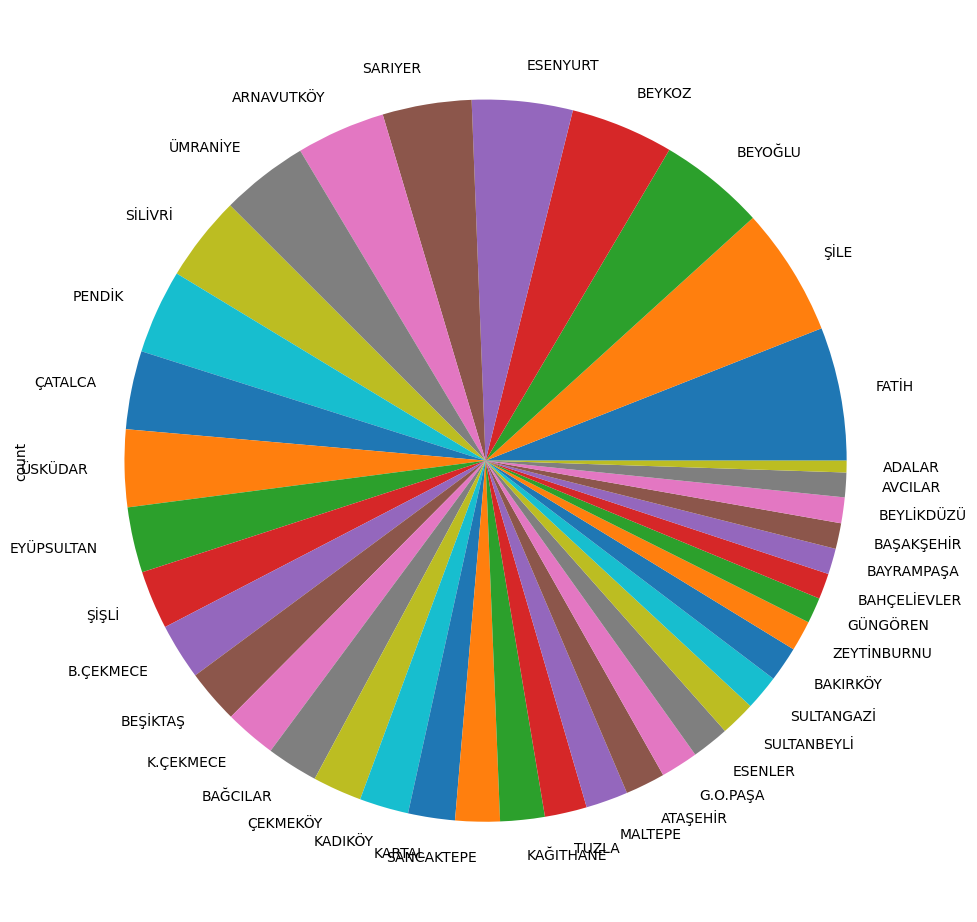

In [140]:
plt.figure(figsize=(10,10))
df["Ilce"].value_counts().plot.pie()
plt.tight_layout()

In [141]:
df.sort_values("Gelen Cagri Sayisi", ascending=False).head()

,Yil,Ilce,Mahalle,Gelen Cagri Sayisi,Cevaplanan Cagri Sayisi
1693,2020,SİLİVRİ,SELİMPAŞA MAH,716,716
1536,2020,K.ÇEKMECE,HALKALI MERKEZ MAH,667,655
1003,2020,ATAŞEHİR,İÇERENKÖY MAH,613,613
1078,2020,BAŞAKŞEHİR,GÜVERCİNTEPE MAH,589,589
1384,2020,FATİH,AKSARAY MAH,540,540


In [176]:
df["Cevaplanmayan Cagri Sayisi"]=df["Gelen Cagri Sayisi"]-df["Cevaplanan Cagri Sayisi"]
df.sort_values("Cevaplanmayan Cagri Sayisi", ascending=False).head()

,Yil,Ilce,Mahalle,Gelen Cagri Sayisi,Cevaplanan Cagri Sayisi,Cevaplanmayan Cagri Sayisi
947,2019,ŞİŞLİ,MERKEZ MAH,277,228,49
938,2019,ŞİŞLİ,GÜLBAHAR MAH,193,165,28
940,2019,ŞİŞLİ,HALİDE EDİP ADIVAR MAH,122,96,26
946,2019,ŞİŞLİ,MECİDİYEKÖY MAH,203,182,21
953,2019,ŞİŞLİ,İZZET PAŞA MAH,119,99,20


Gelen çağrıların yüzde kaçı cevaplandı?

In [151]:
df["Cevaplanan Cagri Sayisi"].sum()/df["Gelen Cagri Sayisi"].sum()*100

np.float64(99.34877741562674)

In [143]:
df.groupby("Ilce").agg({
    "Gelen Cagri Sayisi":["mean","size","sum","min","max"],
    "Cevaplanan Cagri Sayisi":["mean","size","sum","min","max"]
}).sort_values(("Gelen Cagri Sayisi","mean"),ascending=False).head()

Gelen Cagri Sayisi                     Cevaplanan Cagri Sayisi  \
                           mean size   sum min  max                    mean   
Ilce                                                                          
SULTANGAZİ           181.000000   30  5430  16  449              181.000000   
KAĞITHANE            178.105263   38  6768  48  432              177.973684   
BAŞAKŞEHİR           165.272727   22  3636  10  589              164.590909   
BAHÇELİEVLER         147.500000   22  3245  50  314              146.227273   
K.ÇEKMECE            135.363636   44  5956   5  667              135.022727   

                                  
             size   sum min  max  
Ilce                              
SULTANGAZİ     30  5430  16  449  
KAĞITHANE      38  6763  48  432  
BAŞAKŞEHİR     22  3621  10  589  
BAHÇELİEVLER   22  3217  50  311  
K.ÇEKMECE      44  5941   5  655

In [144]:
df["Cevaplanmayan Cagri Sayisi"].sum()

np.int64(1003)

In [145]:
df.groupby("Ilce").agg({
    "Cevaplanmayan Cagri Sayisi": ["size","sum","min","max"]
}).head()

Cevaplanmayan Cagri Sayisi            
                                 size sum min max
Ilce                                             
ADALAR                             10  34   0  15
ARNAVUTKÖY                         76   1   0   1
ATAŞEHİR                           34   2   0   2
AVCILAR                            21   0   0   0
B.ÇEKMECE                          48   5   0   3

In [146]:
a=df.groupby("Ilce").agg({
    "Cevaplanmayan Cagri Sayisi":["size","sum"]
})
toplam=a["Cevaplanmayan Cagri Sayisi"]["sum"].sum()
a["percentage"]=a["Cevaplanmayan Cagri Sayisi"]["sum"].div(toplam)*100

In [147]:
a.sort_values("percentage",ascending=False,inplace=True)
a.head()

Cevaplanmayan Cagri Sayisi      percentage
                              size  sum           
Ilce                                              
ŞİŞLİ                           50  282  28.115653
BEYOĞLU                         91  143  14.257228
ŞİLE                           110  103  10.269192
SARIYER                         76   50   4.985045
SİLİVRİ                         73   49   4.885344

Text(0.5, 1.0, 'ilceler bazinda toplam cevaplanmayan cagri sayisi')

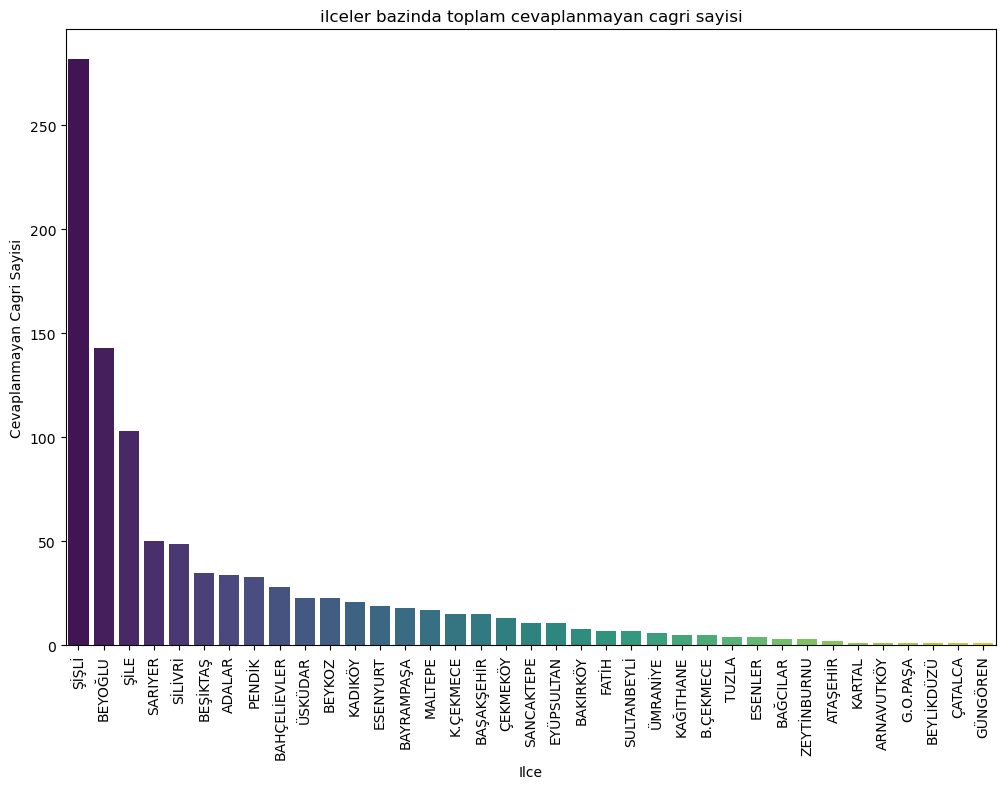

In [148]:
sns.barplot(
    a[a["Cevaplanmayan Cagri Sayisi"]["sum"]>0]["Cevaplanmayan Cagri Sayisi"]["sum"],palette="viridis"
)
plt.xticks(rotation=90)
plt.ylabel("Cevaplanmayan Cagri Sayisi")
plt.title("ilceler bazinda toplam cevaplanmayan cagri sayisi")

In [149]:
df_grafik = df[df["Cevaplanmayan Cagri Sayisi"] > 0]

px.sunburst(
    df_grafik, 
    path=["Ilce", "Mahalle"],
    values="Cevaplanmayan Cagri Sayisi",
    hover_data=["Gelen Cagri Sayisi"],
    color="Cevaplanmayan Cagri Sayisi",
    color_continuous_scale="RdBu_r"
)